<a href="https://colab.research.google.com/github/Kwasi-Dankwa/Expense_Claim_Automation/blob/main/MLS_Week14_Single_Agent_Systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><p float="center">
  <img src="https://vectorseek.com/wp-content/uploads/2023/08/Massachusetts-Institute-of-Technology-MIT-Logo-Vector.svg-.png" width="360"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200"/>
</p></center>

<center><font size=10><b>AI and Data Science</b></font></center>
<center><font size=6><b>MLS : Designing and Building Agentic AI Workflows</b></font></center>

# **1. Problem Statement**

## **1.1 Business Context**

**Automated Expense Claim Processing Using an Agentic System**

Northbridge Analytics is a consulting firm headquartered in Chicago with about 1,200 employees. Its consultants regularly dine with clients, and the finance team reviews around 600 meal receipts every month.

Each review follows the same steps: read the itemized receipt, separate food from alcohol, check every item against the company expense policy, recalculate the sales tax and tip on the eligible items, and write up the claim. Done by hand, this process is slow and error-prone. Reviewers miss alcohol buried in a long receipt or reimburse the tax and tip on the full bill, including the drinks the policy excludes. Errors lead to overpayments, rework, and delays in reimbursing employees.

In this session, we process a receipt from a client dinner at a Chicago restaurant, where the bill mixes food with alcoholic drinks.

## **1.2 Objective**

Build a **single-agent system** that turns a receipt image into a policy-compliant expense claim report. The agent decides which tools to use and in what order, calls them, and uses their results to write the final report.

The agent uses four tools:

- **Text Extractor:** Reads the receipt image with the LLM and extracts the date, check number, restaurant details, items, sales tax, tip, and total.
- **Categorizer:** Sorts each item into one of three categories: Food, Non-Alcoholic Drinks, or Alcoholic Drinks.
- **Verifier:** Retrieves the relevant sections of the company policy by similarity search and separates reimbursable items from excluded ones.
- **Calculator:** Computes the reimbursable subtotal, sales tax, tip, and total.

We then extend the agent in two ways covered in the Week 14 videos:

- **Tool selection (14.18):** The agent picks the tools relevant to a task by matching the task against tool descriptions.
- **Reflection (14.17):** A reviewer step checks the draft report against the policy and sends it back for revision when it finds a problem.

The diagram below shows how the receipt moves through the four tools to become a claim report.

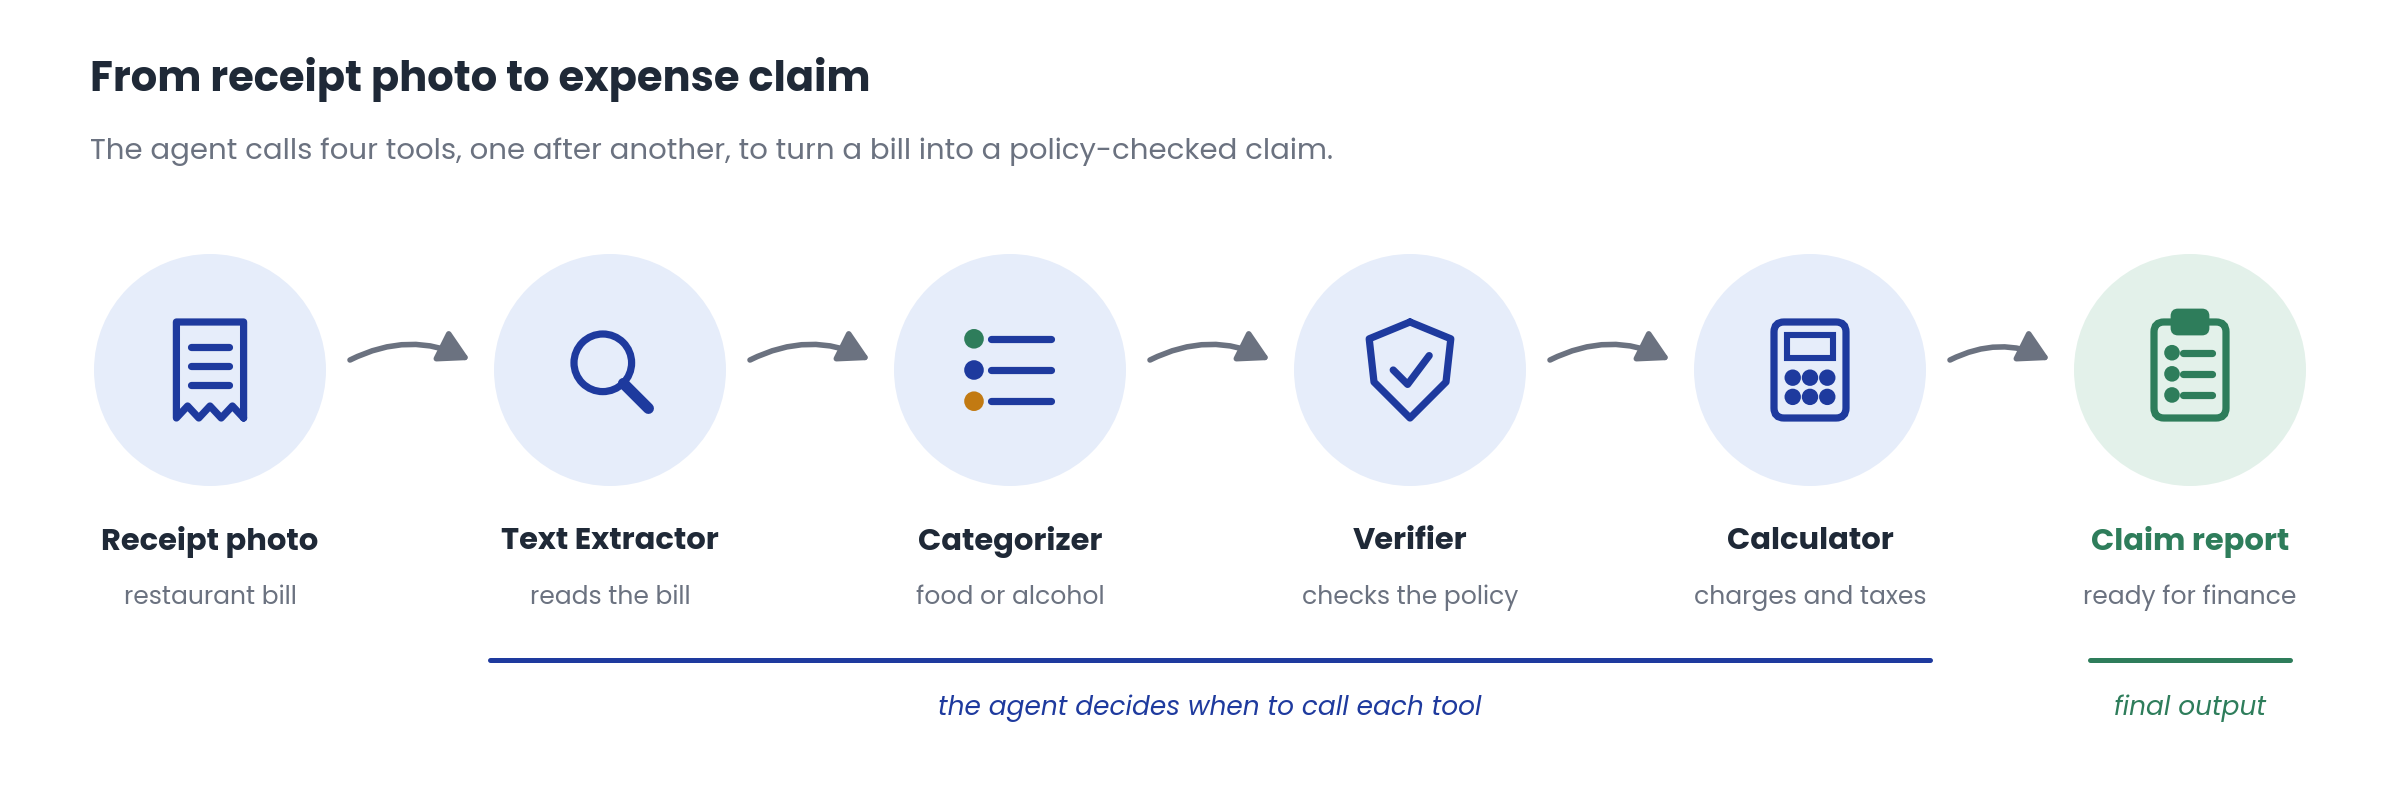

## **1.3 Data Description**

The notebook uses two files.

**Receipt image: `restaurant-bill.jpg`**

A phone photo of an itemized restaurant receipt from a client dinner at Wicker Park Tavern, Chicago, dated 10/08/2026 (Check #4821). All amounts are in US dollars.

| Item | Qty | Amount ($) |
| --- | --- | --- |
| Craft IPA | 2 | 16.00 |
| Buffalo Wings | 1 | 14.00 |
| Moscow Mule | 1 | 13.00 |
| Margherita Flatbread | 1 | 17.00 |
| House Cabernet Gls | 1 | 13.00 |
| Caesar Salad | 1 | 12.00 |
| Sparkling Water | 1 | 5.00 |

| Charge | Amount ($) |
| --- | --- |
| Subtotal | 90.00 |
| Sales Tax (10.25%) | 9.23 |
| Total | 99.23 |
| Tip (20%) | 18.00 |
| Total Paid | 117.23 |

**Company policy: `Company Policy on Expense Claims.pdf`**

A 3-page policy with sections on travel, hotel stays, business lunch and dinner (restaurant) claims, submission guidelines, and policy exceptions. The restaurant section sets the rules for this claim:

- Alcoholic beverages are strictly non-reimbursable.
- Food and non-alcoholic drinks consumed during business meals are reimbursable.
- Claims require itemized receipts that separate food and drink expenses.
- Reasonable tips, typically up to 15 to 20% of the meal cost, are reimbursable.

# **2. Installing and Importing the Necessary Libraries**

- `openai` is the official OpenAI SDK used under the hood by `langchain-openai`.
- `langchain` provides the building blocks for LLM applications: tools, prompts, and document handling.
- `langchain-openai` connects LangChain to OpenAI chat and embedding models.
- `langchain-text-splitters` splits the policy text into smaller chunks for search.
- `langgraph` builds the agent as a graph of nodes and edges with a shared state.
- `pypdf` reads the text from the policy PDF.
- `numexpr` evaluates math expressions for the calculator tool.

In [1]:
# Install the latest compatible versions
!uv pip install -q openai langchain langchain-openai langchain-text-splitters langgraph pypdf numexpr

**Note:**

- After running the install cell above, restart the runtime (for Google Colab) or the notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- You might see a warning about package dependencies. You can ignore it: the command above installs all the libraries and dependencies this notebook needs.

**Optional: check the installed versions**

Run the cell below to see which version of each library got installed. To use a specific version of a library, install it like this:

`!pip install -q library-name==version`

For example: `!pip install -q langgraph==1.2.16`

In [2]:
# Optional: check the installed versions
!pip show openai langchain langchain-openai langchain-text-splitters langgraph pypdf numexpr

Name: openai
Version: 2.54.0
Summary: The official Python library for the openai API
Home-page: https://github.com/openai/openai-python
Author: 
Author-email: OpenAI <support@openai.com>
License: Apache-2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: anyio, distro, httpx, jiter, pydantic, sniffio, tqdm, typing-extensions
Required-by: langchain-openai
---
Name: langchain
Version: 1.4.7
Summary: Building applications with LLMs through composability
Home-page: https://docs.langchain.com/
Author: 
Author-email: 
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: langchain-core, langgraph, pydantic
Required-by: 
---
Name: langchain-openai
Version: 1.7.3
Summary: An integration package connecting OpenAI and LangChain
Home-page: https://docs.langchain.com/oss/python/integrations/providers/openai
Author: 
Author-email: 
License: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: certifi, langchain-core, openai, tiktoken
Required-by: 
---
Name:

## **2.1 Importing the Libraries**

In [3]:
# Standard libraries
import base64   # Encodes the receipt image as text so it can be sent to the LLM
import json     # Parses the JSON returned by the tools
import math     # Math constants for the calculator tool
import re       # Pulls the final total out of the report text
import uuid     # Generates unique IDs for the tool registry
from typing import Annotated, TypedDict  # Type hints for the agent state

import numexpr  # Evaluates math expressions safely in the calculator tool
from pypdf import PdfReader  # Reads the text from the policy PDF
from IPython.display import Markdown, Image, display  # Displays reports and images in the notebook

# LangChain: OpenAI chat and embedding models
from langchain_openai import ChatOpenAI, OpenAIEmbeddings

# LangChain: messages, documents, vector store, tools, and text splitting
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_core.tools import StructuredTool
from langchain_text_splitters import RecursiveCharacterTextSplitter

# LangGraph: graph building blocks and prebuilt nodes
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

In [5]:
import os

from google.colab import userdata # Access user-specific data securely

# Use the secret name you configured in Colab Secrets (e.g., 'openai_api_key' or 'OPENAI_API_KEY').
openai_api_key = userdata.get('OPENAI_API_KEY')

## **2.2 Setting Up the LLM and the Embedding Model**

We load the API key from Colab Secrets, as described in the Week 14 content pages *Instructions: GL OpenAI Access Token* and *How to Add Your API Key to Google Colab Secrets*.

In [6]:
# Load the OpenAI API key from Colab Secrets
from google.colab import userdata
openai_api_key = userdata.get('openai_api_key')

SecretNotFoundError: Secret openai_api_key does not exist.

**Handling temporary proxy errors**

Every LLM and embedding call in this notebook goes through the Great Learning proxy. Now and then, the proxy rejects a valid request with a temporary error, such as `401: You didn't provide an API key`, and the same request succeeds a moment later. The OpenAI library does not retry a 401 on its own, so one failed call would stop the whole agent run.

We add a small retry layer with `tenacity`, a library that installs with LangChain. When a call fails with a temporary error, it waits a few seconds and tries again, up to 4 attempts. If the error is still there after 4 attempts, it is shown as usual, which usually means the API key itself needs checking.

In [7]:
import openai
from tenacity import retry, retry_if_exception_type, stop_after_attempt, wait_exponential

# Errors the GL proxy can return for a moment before it recovers
TEMPORARY_ERRORS = (
    openai.AuthenticationError,
    openai.APIConnectionError,
    openai.APITimeoutError,
    openai.RateLimitError,
    openai.InternalServerError,
)

# Retry a failed call up to 4 times in total, waiting 2, 4, then 8 seconds between attempts
retry_temporary_errors = retry(
    retry=retry_if_exception_type(TEMPORARY_ERRORS),
    stop=stop_after_attempt(4),
    wait=wait_exponential(multiplier=1, min=2, max=8),
    reraise=True,
)


class RetryingChatOpenAI(ChatOpenAI):
    """ChatOpenAI that retries a call when the proxy returns a temporary error."""

    @retry_temporary_errors
    def _generate(self, *args, **kwargs):
        return super()._generate(*args, **kwargs)


class RetryingOpenAIEmbeddings(OpenAIEmbeddings):
    """OpenAIEmbeddings that retries a call when the proxy returns a temporary error."""

    @retry_temporary_errors
    def embed_documents(self, *args, **kwargs):
        return super().embed_documents(*args, **kwargs)

We use **GPT-5.6 Luna**, the fastest and most cost-efficient model in OpenAI's GPT-5.6 family. It reads images and supports function calling, which this agent needs.

GPT-5.6 models are reasoning models: they can think before answering. `reasoning_effort` controls how much. We set it to `"none"` so each of the agent's many LLM calls returns quickly during the session; raise it to `"low"` or `"medium"` if you see categorization or calculation errors. Reasoning models do not take a `temperature` setting the way `gpt-4o-mini` in the Week 14 hands-on notebook does, so we leave it out.

In [8]:
# Chat model used by the agent and by the LLM-backed tools
llm = RetryingChatOpenAI(
    api_key=openai_api_key,
    base_url="https://aibe.mygreatlearning.com/openai/v1",
    model="gpt-5.6-luna",
    reasoning_effort="none"
)

# Embedding model used for the policy vector store and the tool registry
embedding_model = RetryingOpenAIEmbeddings(
    api_key=openai_api_key,
    base_url="https://aibe.mygreatlearning.com/openai/v1",
    model="text-embedding-3-small"
)

Let us confirm the model responds.

In [9]:
print(llm.invoke("Reply with: LLM is ready").content)

LLM is ready


# **3. Loading the Data**

> **Note:** Before running the cells below, upload `restaurant-bill.jpg` and `Company Policy on Expense Claims.pdf` (from the provided zip file) to the Colab session storage.

In [10]:
# Receipt image to process
input_bill_path = "restaurant-bill.jpg"

# Employee submitting the claims and the type of expense
employee_name = "Emily Carter"
type_of_expense = "Restaurant"

# Company expense policy
company_policy_file_path = "Company Policy on Expense Claims.pdf"

Let us look at the receipt. It is a phone photo of a printed receipt on a table, taken at a slight angle and with fold creases, so the text extractor has to read text that is not perfectly straight.

The receipt mixes three alcoholic drinks (Craft IPA, Moscow Mule, and House Cabernet), which the policy does not reimburse, with three food items and a sparkling water.

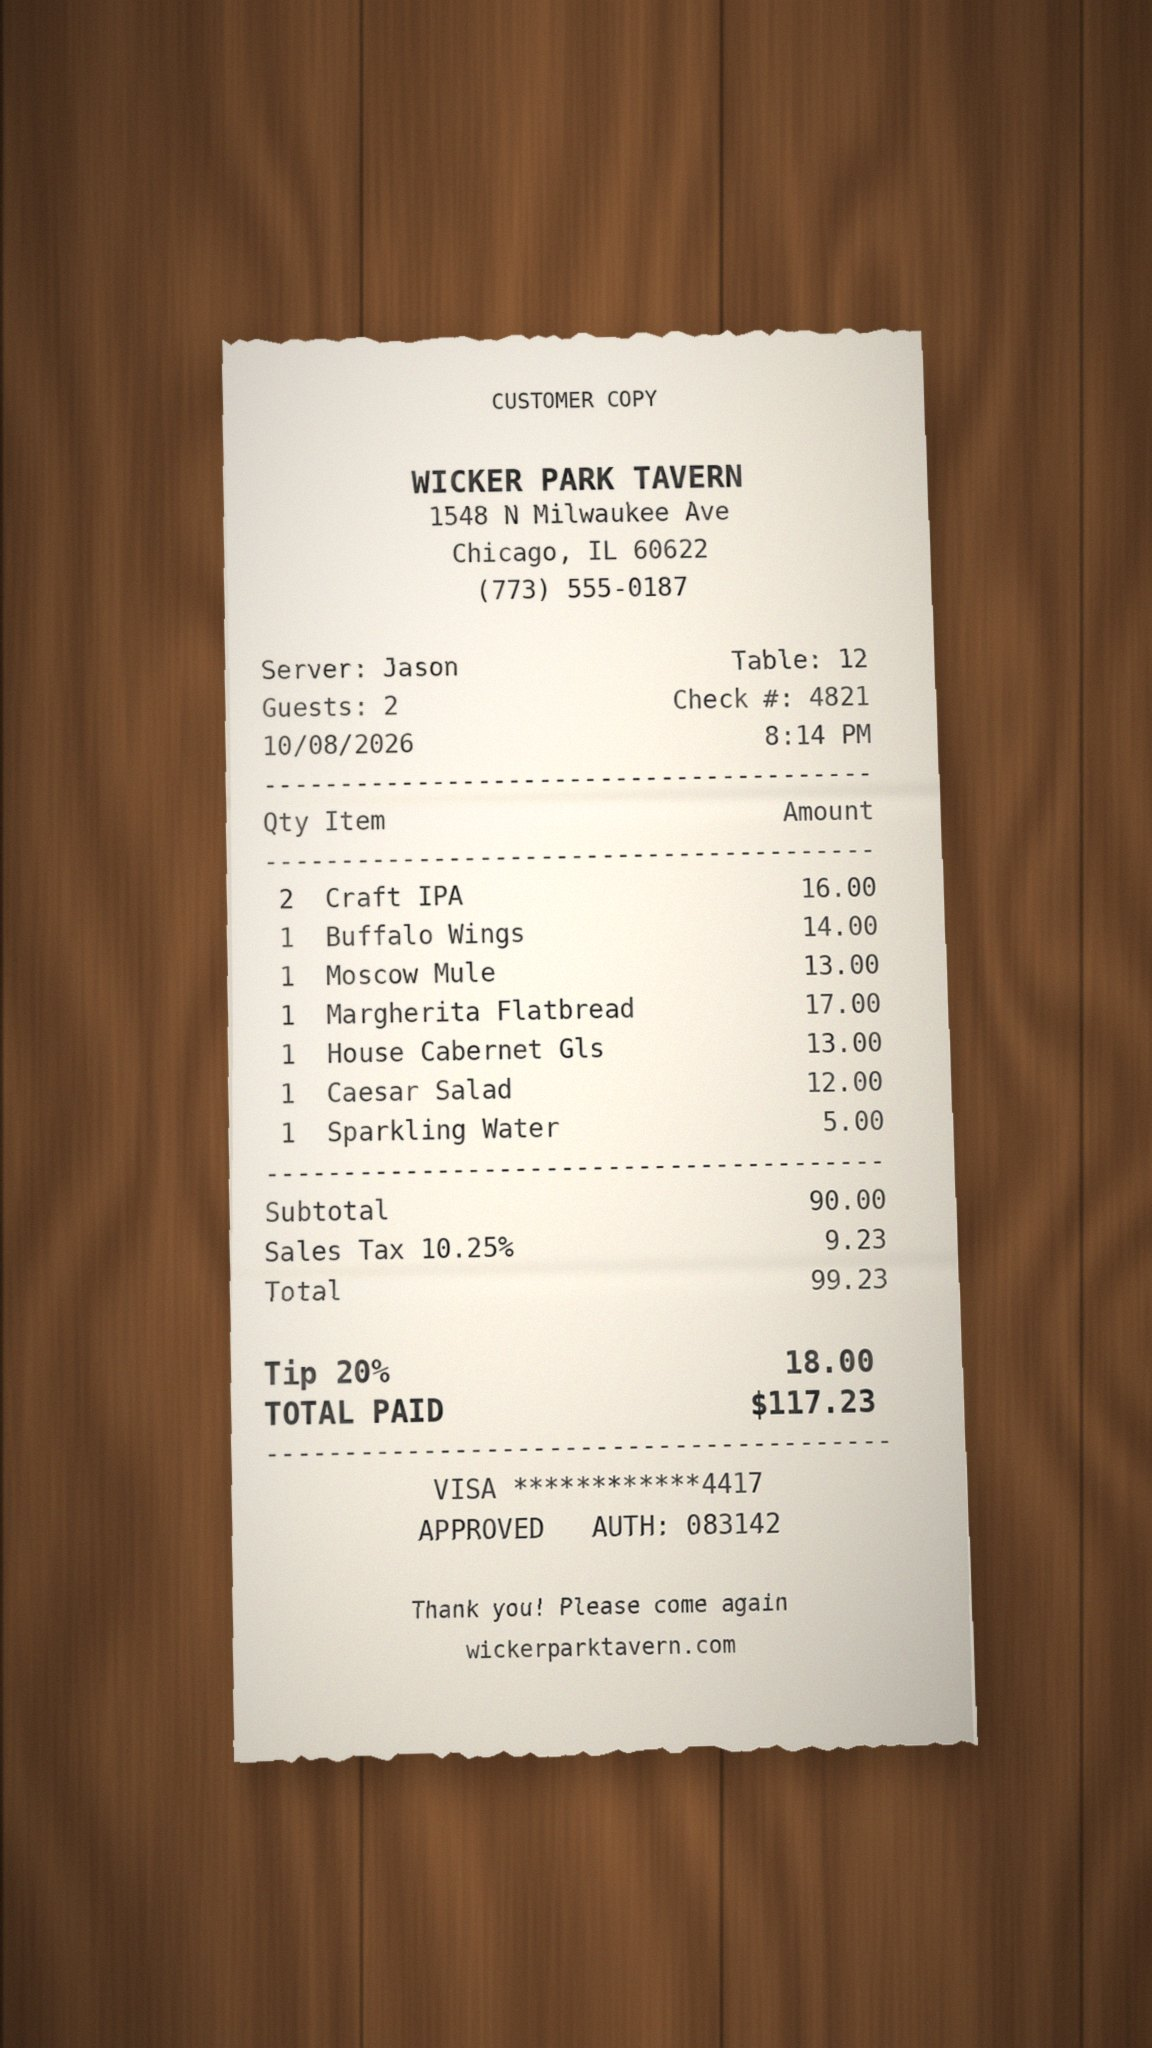

In [11]:
display(Image(filename=input_bill_path, width=320))

## **3.1 Loading and Chunking the Policy**

This follows the retrieval pattern from the Retrieval Augmented Generation (RAG) videos in the Generative AI and Agentic AI Foundations module: load the document, split it into chunks, embed each chunk, and store the embeddings so we can search them by similarity.

The text extracted from this PDF contains a line break after almost every word, so we first collapse the extra whitespace. Clean text gives better chunks and better embeddings.

The diagram below shows the steps from the policy PDF to a similarity search result.

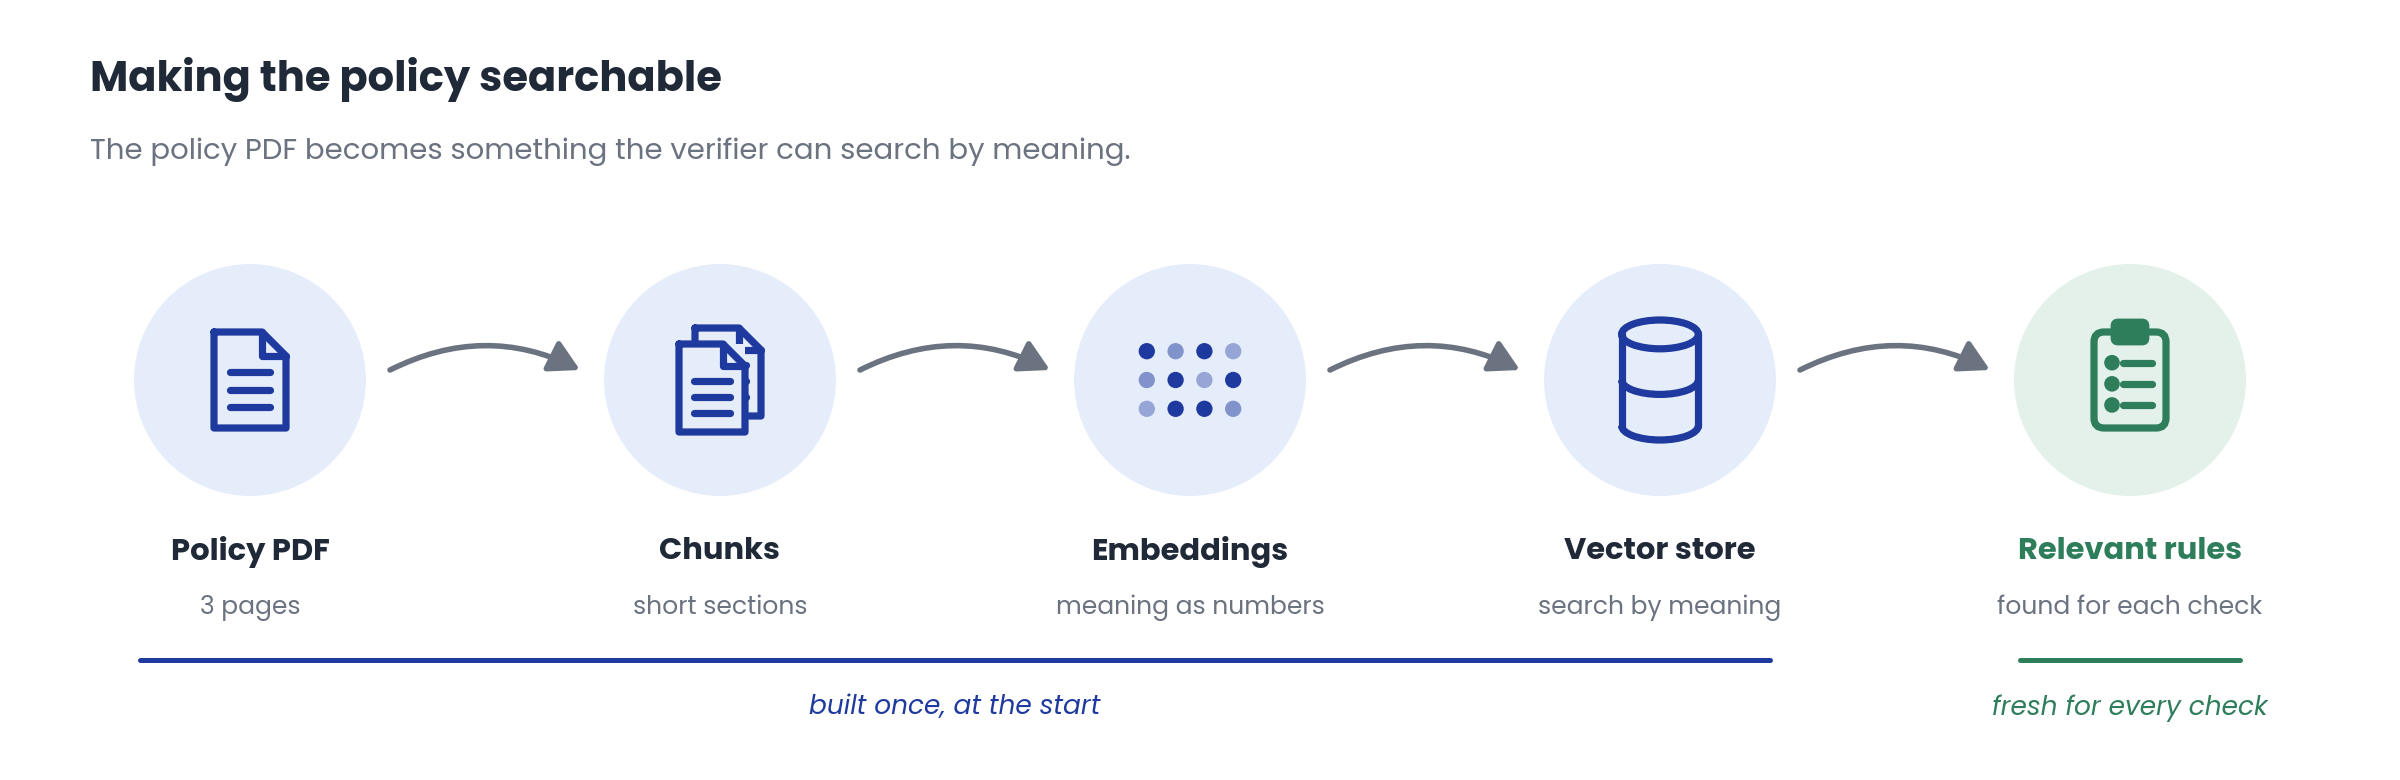

In [12]:
# Read each page of the policy PDF and store it as a LangChain Document
# The text from this PDF has a line break after almost every word, so we collapse the extra whitespace
reader = PdfReader(company_policy_file_path)
company_policy_pages = [
    Document(
        page_content=" ".join((page.extract_text() or "").split()),
        metadata={"source": company_policy_file_path, "page": page_number},
    )
    for page_number, page in enumerate(reader.pages)
]

# Split the pages into smaller chunks so each search returns a focused section
text_splitter = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=100)
company_policy_chunks = text_splitter.split_documents(company_policy_pages)

print(f"Pages loaded: {len(company_policy_pages)}")
print(f"Chunks created: {len(company_policy_chunks)}")

Pages loaded: 3
Chunks created: 12


## **3.2 Creating the Policy Vector Store**

In [13]:
# Create an in-memory vector store and add the policy chunks as embeddings
company_policy_vector_store = InMemoryVectorStore(embedding=embedding_model)
policy_chunk_ids = company_policy_vector_store.add_documents(company_policy_chunks)

print(f"Policy chunks stored: {len(policy_chunk_ids)}")

Policy chunks stored: 12


Let us test the vector store with a question about alcohol.

In [14]:
# Retrieve the policy chunk most similar to the question
results = company_policy_vector_store.similarity_search("Are alcoholic drinks reimbursable?", k=1)
print(results[0].page_content)

beverages are strictly non-reimbursable. Employees must ensure that no claims are submitted for alcoholic drinks included in meal receipts. It is recommended to request itemized bills from the restaurant to distinguish between alcoholic and non-alcoholic items. 2. Non-Alcoholic Drinks : Non-alcoholic beverages, including water, soft drinks, tea, and coffee, are fully reimbursable, provided they are consumed as part of a business meal. Itemized receipts must be attached to the expense claim. 3. Food Items : The cost of food consumed during business meals is reimbursable. Employees should


# **4. Defining the Tools**

In the Week 14 hands-on notebook, each tool was a plain Python function that looked up a dictionary. Here, three of the four tools call the LLM inside the function.

To the agent, nothing changes: it still sees each tool's name, description, and inputs, and it receives a string back. The difference sits inside the tool. Wrapping an LLM call in a tool lets us give each step its own focused prompt, which is easier to test and improve than one large prompt.

We also add a small helper that parses JSON returned by the LLM. LLMs sometimes wrap JSON in code fences, which breaks `json.loads`.

In [15]:
def parse_json(text: str):
    """Parses JSON returned by the LLM, removing code fences if present."""
    cleaned = text.strip().replace("```json", "").replace("```", "").strip()
    return json.loads(cleaned)

## **4.1 Tool 1: Text Extractor**

The LLM accepts images as well as text. To send an image, we read the file, encode it as base64 text, and pass it in a message with the type `image_url`. GPT-5.6 Luna reads the receipt and returns its details as text.

In [16]:
def text_extractor(jpg_file_path: str) -> str:
    """
    Reads a receipt image and extracts its details with the LLM.

    Args:
        jpg_file_path: The local file path to the JPG image of the receipt.

    Returns:
        The extracted receipt details as text.
    """
    # Read the image file and encode it as base64 text
    with open(jpg_file_path, "rb") as image_file:
        base64_encoded_data = base64.b64encode(image_file.read()).decode("utf-8")
    data_uri = f"data:image/jpeg;base64,{base64_encoded_data}"

    text_extraction_system_message = """
    You are an expert at reading restaurant receipts.
    Extract the following details from the receipt image:
    - Date
    - Check number
    - Restaurant name and address
    - Currency
    - Each item with its quantity, rate, and amount
    - Subtotal
    - Sales tax rate and amount
    - Tip percentage and amount
    - Total paid

    Report every value exactly as printed. Do not output anything except these details.
    """

    messages = [
        SystemMessage(content=text_extraction_system_message),
        HumanMessage(content=[{"type": "image_url", "image_url": {"url": data_uri}}])
    ]
    response = llm.invoke(messages)
    return response.content

Next, we wrap the function as a tool with `StructuredTool.from_function`, as in the Week 14 hands-on notebook. The description matters twice here: the agent reads it to decide when to call the tool, and the tool selection step later searches these descriptions.

In [17]:
extractor_tool = StructuredTool.from_function(
    text_extractor,
    name="text_extractor",
    description="""
    Reads a receipt image file and extracts the bill details: date, check number,
    restaurant name and address, items with quantity and amount, subtotal, sales tax rate,
    tip percentage, and total paid. Input: the file path of the receipt image.
    """
)

Let us test the tool on the receipt.

In [18]:
extracted_text = text_extractor(input_bill_path)
print(extracted_text)

Date: 10/08/2026
Check number: 4821
Restaurant name and address: WICKER PARK TAVERN, 1548 N Milwaukee Ave, Chicago, IL 60622
Currency: $
Items:
- Quantity: 2, Rate: 8.00, Amount: 16.00, Craft IPA
- Quantity: 1, Rate: 14.00, Amount: 14.00, Buffalo Wings
- Quantity: 1, Rate: 13.00, Amount: 13.00, Moscow Mule
- Quantity: 1, Rate: 17.00, Amount: 17.00, Margherita Flatbread
- Quantity: 1, Rate: 13.00, Amount: 13.00, House Cabernet Gls
- Quantity: 1, Rate: 12.00, Amount: 12.00, Caesar Salad
- Quantity: 1, Rate: 5.00, Amount: 5.00, Sparkling Water
Subtotal: 90.00
Sales tax rate and amount: 10.25%, 9.23
Tip percentage and amount: 20%, 18.00
Total paid: $117.23


## **4.2 Tool 2: Categorizer**

The categorizer sorts each item into one of three categories and returns JSON, so the next tool can work with structured data.

In [19]:
def categorizer(extracted_text: str) -> str:
    """
    Categorizes the items from the extracted receipt text.

    Args:
        extracted_text: The receipt details returned by the text extractor.

    Returns:
        A JSON string listing each item with its category, quantity, and amount.
    """
    categorization_system_message = """
    You are an expert accountant. Categorize every item ordered on the receipt into exactly one
    of these categories: Food, Non-Alcoholic Drinks, Alcoholic Drinks. Do not create new categories.

    Return valid JSON only (double quotes, no code fences), as a list in this format:
    [{"item": "<item name>", "category": "<category>", "quantity": <quantity>, "amount": <line amount>}]
    """
    response = llm.invoke([
        SystemMessage(content=categorization_system_message),
        HumanMessage(content=extracted_text)
    ])
    return response.content

In [20]:
categorizer_tool = StructuredTool.from_function(
    categorizer,
    name="categorizer",
    description="""
    Sorts the items from extracted receipt text into Food, Non-Alcoholic Drinks, and Alcoholic Drinks.
    Input: the text returned by text_extractor. Output: a JSON list of items with category, quantity, and amount.
    """
)

In [21]:
categorized_text = categorizer(extracted_text)
print(categorized_text)

[{"item":"Craft IPA","category":"Alcoholic Drinks","quantity":2,"amount":16.00},{"item":"Buffalo Wings","category":"Food","quantity":1,"amount":14.00},{"item":"Moscow Mule","category":"Alcoholic Drinks","quantity":1,"amount":13.00},{"item":"Margherita Flatbread","category":"Food","quantity":1,"amount":17.00},{"item":"House Cabernet Gls","category":"Alcoholic Drinks","quantity":1,"amount":13.00},{"item":"Caesar Salad","category":"Food","quantity":1,"amount":12.00},{"item":"Sparkling Water","category":"Non-Alcoholic Drinks","quantity":1,"amount":5.00}]


## **4.3 Tool 3: Verifier**

The verifier checks the categorized items against the company policy. It retrieves the policy sections relevant to each category, plus the section on tips and gratuities, and asks the LLM to separate reimbursable items from excluded ones.

It also returns the policy's maximum reimbursable tip rate, so the agent can check whether the tip on the bill is within the policy.

In [22]:
def verifier(categorized_text: str) -> str:
    """
    Verifies categorized receipt items against the company expense policy.

    Args:
        categorized_text: The JSON list of items returned by the categorizer.

    Returns:
        A JSON string with reimbursable items, excluded items with reasons, and the maximum tip rate.
    """
    # Step 1: Find the unique categories on the receipt
    categories = {item["category"] for item in parse_json(categorized_text)}

    # Step 2: Retrieve the policy sections for each category, plus the tip rules
    search_queries = [f"Are {category} reimbursable?" for category in categories]
    search_queries.append("Tips and gratuities reimbursement limit")

    relevant_chunks = []
    for query in search_queries:
        relevant_chunks.extend(company_policy_vector_store.similarity_search(query, k=2))
    relevant_policy = "\n\n".join(dict.fromkeys(chunk.page_content for chunk in relevant_chunks))

    # Step 3: Ask the LLM to apply the retrieved policy to the items
    verification_system_message = f"""
    You are an expert accountant. Verify each receipt item against the company policy below.

    Return valid JSON only (double quotes, no code fences) in this format:
    {{
      "reimbursable_items": [{{"item": "<item>", "category": "<category>", "quantity": <quantity>, "amount": <amount>}}],
      "excluded_items": [{{"item": "<item>", "category": "<category>", "amount": <amount>, "reason": "<policy reason>"}}],
      "max_tip_rate": <highest tip rate the policy reimburses, as a decimal, for example 0.20>
    }}

    Company Policy:
    {relevant_policy}
    """
    response = llm.invoke([
        SystemMessage(content=verification_system_message),
        HumanMessage(content=categorized_text)
    ])
    return response.content

In [23]:
verifier_tool = StructuredTool.from_function(
    verifier,
    name="verifier",
    description="""
    Checks categorized receipt items against the company expense policy using similarity search on the policy.
    Input: the JSON returned by categorizer. Output: JSON with reimbursable items, excluded items with reasons,
    and the maximum reimbursable tip rate.
    """
)

In [24]:
verified_text = verifier(categorized_text)
print(verified_text)

{"reimbursable_items":[{"item":"Buffalo Wings","category":"Food","quantity":1,"amount":14.0},{"item":"Margherita Flatbread","category":"Food","quantity":1,"amount":17.0},{"item":"Caesar Salad","category":"Food","quantity":1,"amount":12.0},{"item":"Sparkling Water","category":"Non-Alcoholic Drinks","quantity":1,"amount":5.0}],"excluded_items":[{"item":"Craft IPA","category":"Alcoholic Drinks","amount":16.0,"reason":"Alcoholic beverages are strictly non-reimbursable."},{"item":"Moscow Mule","category":"Alcoholic Drinks","amount":13.0,"reason":"Alcoholic beverages are strictly non-reimbursable."},{"item":"House Cabernet Gls","category":"Alcoholic Drinks","amount":13.0,"reason":"Alcoholic beverages are strictly non-reimbursable."}],"max_tip_rate":0.2}


## **4.4 Tool 4: Calculator**

LLMs make arithmetic mistakes, so the agent hands every calculation to this tool. `numexpr` evaluates the expression without running arbitrary Python code.

In [25]:
def calculator(expression: str) -> str:
    """
    Evaluates a single-line math expression with numexpr.

    Args:
        expression: A math expression, for example "48 * 0.1025".

    Returns:
        The result as a string.
    """
    local_dict = {"pi": math.pi, "e": math.e}
    return str(
        numexpr.evaluate(
            expression.strip(),
            global_dict={},          # Blocks access to Python globals
            local_dict=local_dict,   # Allows common math constants
        )
    )

In [26]:
calculator_tool = StructuredTool.from_function(
    calculator,
    name="calculator",
    description="""
    Evaluates a single-line math expression such as "48 * 0.1025" and returns the number.
    Use it for every subtotal, sales tax, tip, and total calculation.
    """
)

In [27]:
print(calculator("48 * 0.1025"))

4.92


# **5. Tool Registry and Tool Selection**

This agent has four tools, so listing all of them in every prompt costs little. Real agents often have dozens or hundreds of tools. Sending every description with every request wastes tokens and makes it harder for the LLM to pick the right one.

As covered in 14.18 *Smarter Agents: Tool Selection and Memory Use*, we store each tool's description as an embedding and, for each task, retrieve only the tools whose descriptions best match it.

The diagram below shows how the agent picks its tools for a task.

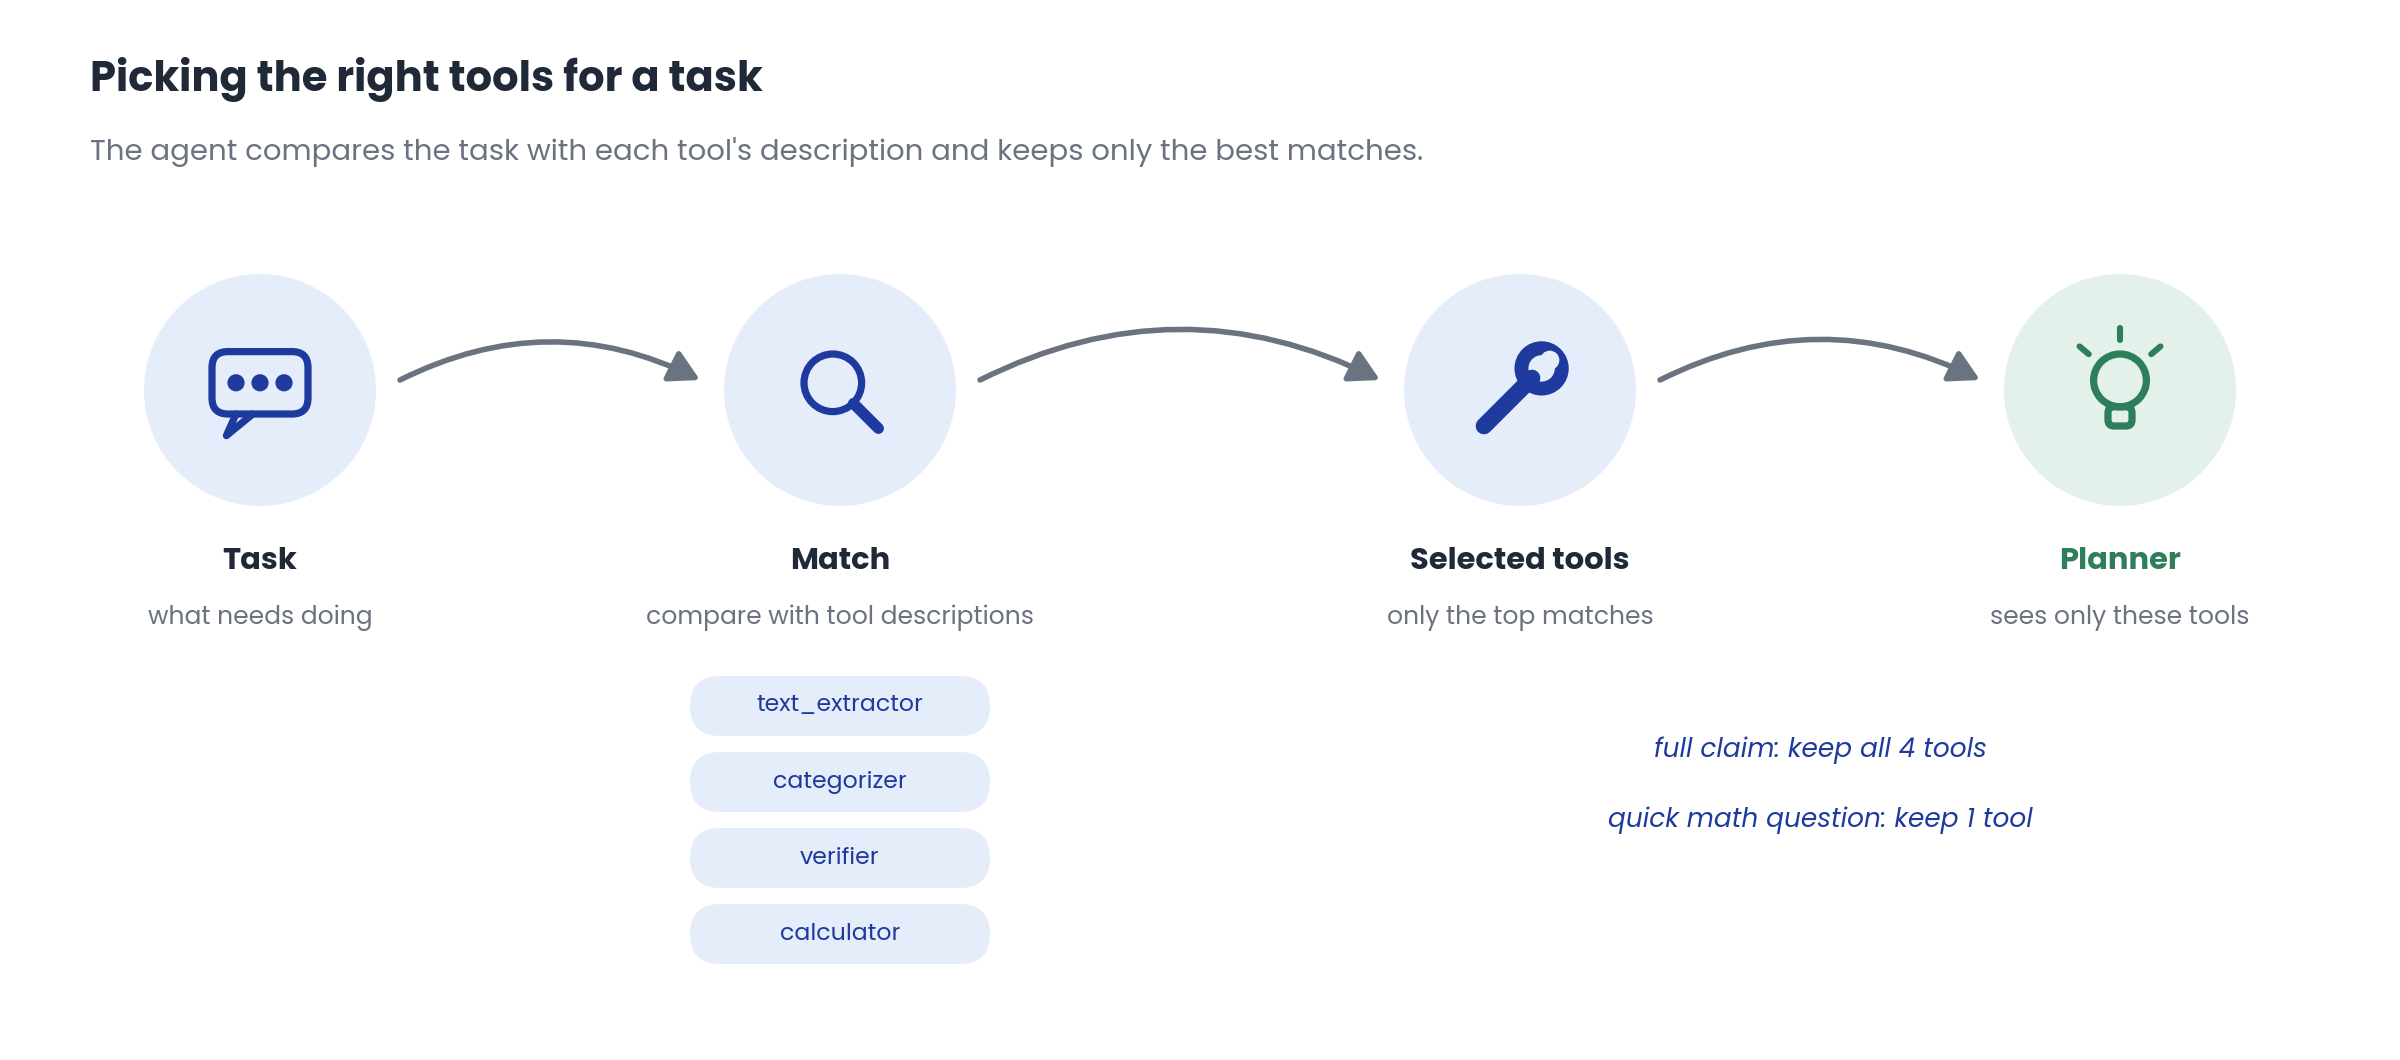

In [28]:
# All tools available to the agent
tools = [extractor_tool, categorizer_tool, verifier_tool, calculator_tool]

# Registry that maps a unique ID to each tool
tool_registry = {str(uuid.uuid4()): tool for tool in tools}

# Turn each tool description into a Document so it can be embedded and searched
tool_documents = [
    Document(page_content=tool.description, id=tool_id, metadata={"tool_name": tool.name})
    for tool_id, tool in tool_registry.items()
]

# Store the tool descriptions in their own vector store
tools_vector_store = InMemoryVectorStore(embedding=embedding_model)
tool_document_ids = tools_vector_store.add_documents(tool_documents)

print(f"Tools registered: {[tool.name for tool in tool_registry.values()]}")

Tools registered: ['text_extractor', 'categorizer', 'verifier', 'calculator']


## **5.1 Tool Selection in Action**

Let us see which two tools the search picks for three different tasks.

In [29]:
sample_tasks = [
    "Read the items and amounts printed on this receipt image",
    "Which of these items does the company policy allow us to reimburse?",
    "What is 20 percent of 48 dollars?",
]

for task in sample_tasks:
    matches = tools_vector_store.similarity_search(task, k=2)
    print(f"Task: {task}")
    print(f"Selected tools: {[match.metadata['tool_name'] for match in matches]}\n")

Task: Read the items and amounts printed on this receipt image
Selected tools: ['text_extractor', 'categorizer']

Task: Which of these items does the company policy allow us to reimburse?
Selected tools: ['verifier', 'text_extractor']

Task: What is 20 percent of 48 dollars?
Selected tools: ['calculator', 'verifier']



Each task brings a different tool to the top of the results. A full expense claim needs all four tools, so we select four tools for claims. For a narrow question, such as a single calculation, we select fewer. The number of tools to select becomes part of the agent's input.

# **6. Building the Agent**

## **6.1 Agent State**

The state holds everything the nodes share as the graph runs:

- `messages`: The conversation, including tool calls and tool results. `add_messages` appends new messages instead of replacing the list.
- `query`: The task text used for tool selection.
- `num_tools`: How many tools to select for this task.
- `selected_tools`: The IDs of the selected tools.
- `reflection_count`, `approved`, `review_notes`: Used in the reflection section later.

In [30]:
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]
    query: str
    num_tools: int
    selected_tools: list[str]
    reflection_count: int
    approved: bool
    review_notes: list[str]

## **6.2 Select Tools Node**

This node searches the tool descriptions using the task text and stores the IDs of the best matches in the state.

In [31]:
def select_tools(state: AgentState):
    num_tools = state.get("num_tools", len(tools))
    matches = tools_vector_store.similarity_search(state["query"], k=num_tools)
    return {"selected_tools": [match.id for match in matches]}

## **6.3 Planner Node**

The planner is the reason step of ReAct, the same role as the `call_model` node in the Week 14 hands-on notebook. It binds only the selected tools to the LLM, so the LLM can call only those tools.

In [32]:
def planner(state: AgentState):
    # Look up the selected tools in the registry
    selected_tools = [tool_registry[tool_id] for tool_id in state["selected_tools"]]

    # Bind the selected tools to the LLM and decide the next step
    llm_with_tools = llm.bind_tools(selected_tools)
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## **6.4 Tool Node**

`ToolNode` runs the tool calls the planner requests and adds the results to the state as `ToolMessage` objects. This is the act step of ReAct.

In [33]:
tool_node = ToolNode(tools=tools)

## **6.5 Agent Workflow**

In the Week 14 hands-on notebook, we wrote `should_continue` by hand: if the last message contains tool calls, go to the tool node; otherwise, end. LangGraph ships the same logic prebuilt as `tools_condition`, which routes to the node named `"tools"` or to `END`.

The edge from `tools` back to `planner` completes the ReAct loop: the planner observes the tool results and decides the next step.

The diagram below shows the workflow we build in this section.

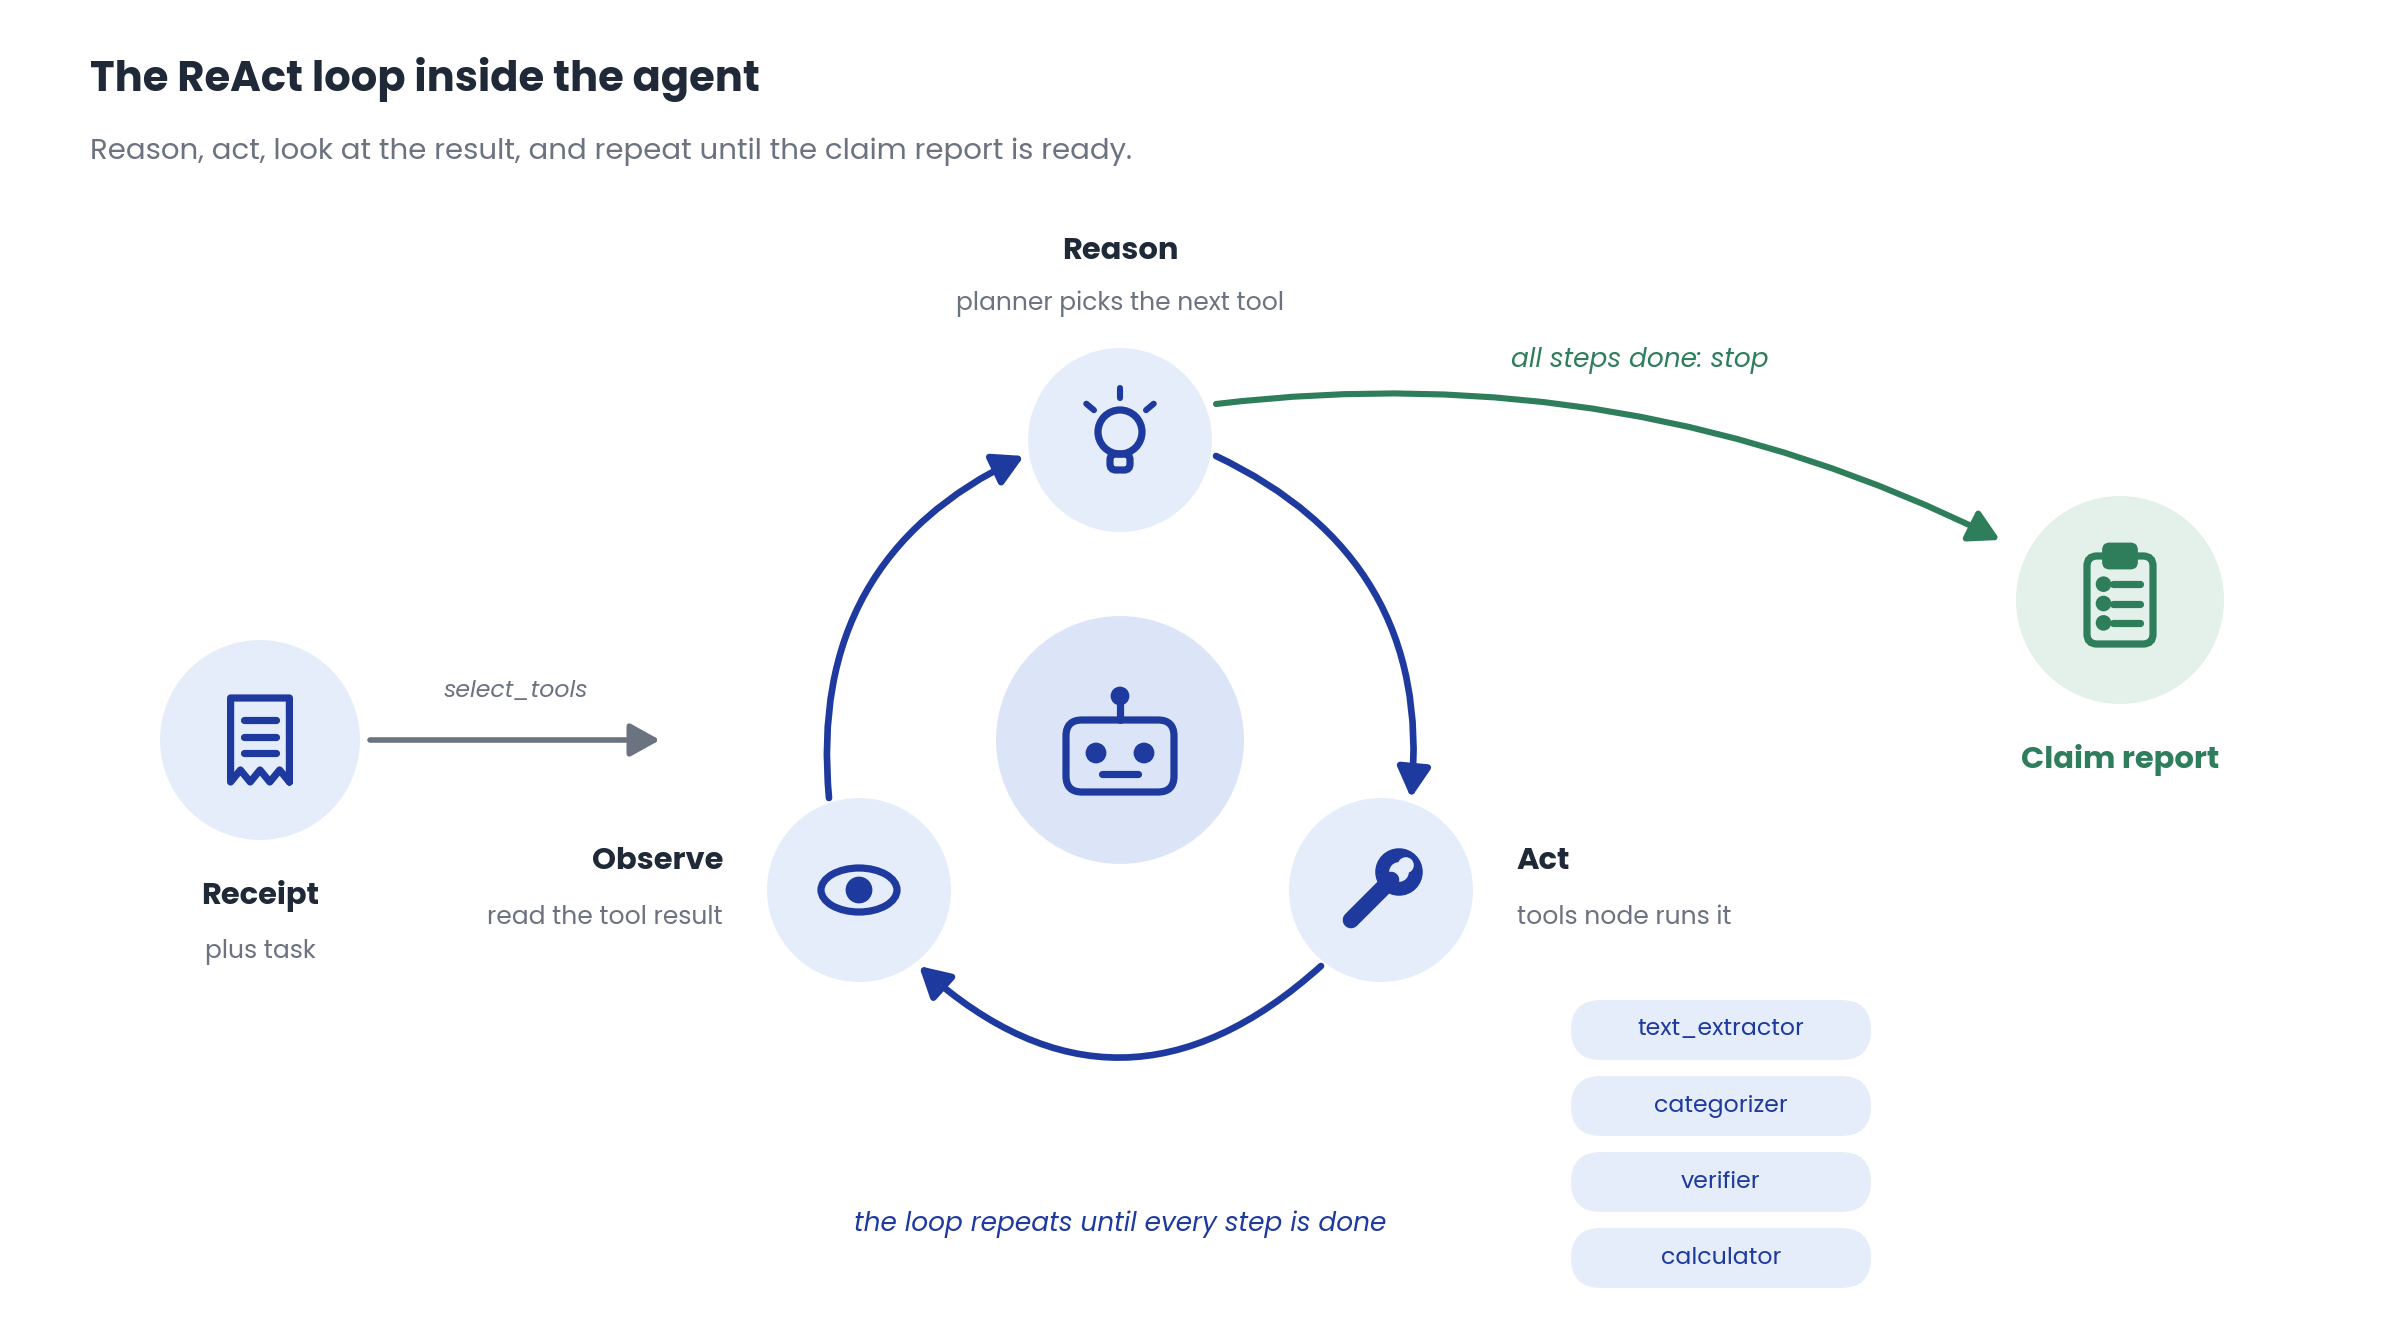

In [34]:
workflow = StateGraph(AgentState)

# Nodes
workflow.add_node("select_tools", select_tools)
workflow.add_node("planner", planner)
workflow.add_node("tools", tool_node)

# Edges
workflow.add_edge(START, "select_tools")
workflow.add_edge("select_tools", "planner")
workflow.add_conditional_edges("planner", tools_condition, ["tools", END])
workflow.add_edge("tools", "planner")

agent_workflow = workflow.compile()

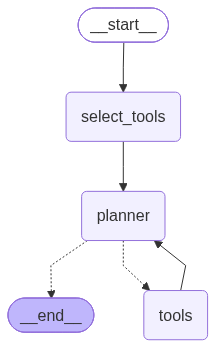

In [35]:
# Visualize the workflow
# Drawing the graph calls an online service, so we skip it if there is no internet access
try:
    display(Image(agent_workflow.get_graph().draw_mermaid_png()))
except Exception:
    print("Could not draw the graph without internet access. The diagram above shows the same workflow.")

# **7. Running the Agent**

## **7.1 Task Instructions**

The system message tells the agent what to produce and how to calculate each amount. The sales tax rate and tip percentage come from the receipt, and the tip limit comes from the verifier.

In [36]:
TASK_MESSAGE = """
You process restaurant receipts into expense claim reports for the finance team.

Steps:
1. Use text_extractor on the receipt image file.
2. Use categorizer on the extracted text.
3. Use verifier on the categorized items.
4. Use calculator for every amount below. Never compute amounts yourself.
   - Reimbursable subtotal = sum of the reimbursable item amounts.
   - Sales tax = reimbursable subtotal x the sales tax rate printed on the receipt.
   - Tip = reimbursable subtotal x the tip percentage printed on the receipt.
     Reimburse the tip only if that percentage is at or below the policy's maximum tip rate from the verifier.
   - Total = reimbursable subtotal + sales tax + tip.
   Round each amount to 2 decimal places.
   Do not reuse the subtotal, tax, or tip amounts printed on the receipt: they include the excluded items.

Present the final report in this markdown format and output nothing else:

# Expense Claim Report
**Employee Name:** <employee name>
**Expense Type:** <expense type>
**Date:** <date on receipt>
**Check No:** <check number>
**Restaurant:** <restaurant name and address>

## Reimbursable Items
| Item | Category | Quantity | Amount (USD) |
| --- | --- | --- | --- |

## Excluded Items
| Item | Category | Amount (USD) | Reason |
| --- | --- | --- | --- |
(Write "None" if no items are excluded.)

## Reimbursement Summary
- Reimbursable Subtotal: $<amount>
- Sales Tax (<rate>%): $<amount>
- Tip (<rate>%): $<amount>
- **Total Amount to Be Reimbursed: $<amount>**
"""

## **7.2 Helper Functions**

These helpers send the receipt to an agent, pull out the final report, and list the tools the agent called in order.

In [37]:
def process_claim(agent, receipt_path: str, num_tools: int = 4):
    """Runs an agent on one receipt and returns the final state."""
    user_message = (
        f"Process the expense claim for employee {employee_name}. "
        f"Expense type: {type_of_expense}. Receipt image file: {receipt_path}"
    )
    return agent.invoke({
        "messages": [SystemMessage(content=TASK_MESSAGE), HumanMessage(content=user_message)],
        "query": user_message,
        "num_tools": num_tools,
        "reflection_count": 0,
        "approved": False,
        "review_notes": [],
    })


def get_report(result) -> str:
    """Returns the content of the last AI message, which holds the final report."""
    ai_messages = [m for m in result["messages"] if isinstance(m, AIMessage) and m.content]
    return ai_messages[-1].content if ai_messages else ""


def get_tool_sequence(result) -> list:
    """Lists the tools the agent called, in order."""
    return [m.name for m in result["messages"] if isinstance(m, ToolMessage)]


def extract_total(report: str):
    """Pulls the total reimbursement amount out of the report."""
    match = re.search(r"Total Amount to Be Reimbursed:\**\s*\$?\s*([\d,]+\.\d{2})", report)
    return float(match.group(1).replace(",", "")) if match else None

## **7.3 Expected Reimbursement**

To check the agent, we first work out the correct reimbursement by applying the policy to the receipt:

- The three alcoholic drinks ($42.00: two Craft IPAs, a Moscow Mule, and a House Cabernet) are excluded, which leaves the wings, flatbread, salad, and sparkling water: $48.00.
- The receipt charges 10.25% sales tax on the full $90.00 subtotal. Only the tax on the eligible $48.00 is reimbursed: $4.92.
- The 20% tip is within the policy's 15 to 20% guideline, so it is reimbursed on the eligible amount: $9.60.
- The correct claim is $62.52, against $117.23 paid. Reusing the receipt's own tax ($9.23) and tip ($18.00) would overpay by $12.71.

The diagram below shows how the bill splits into the reimbursed and excluded parts.

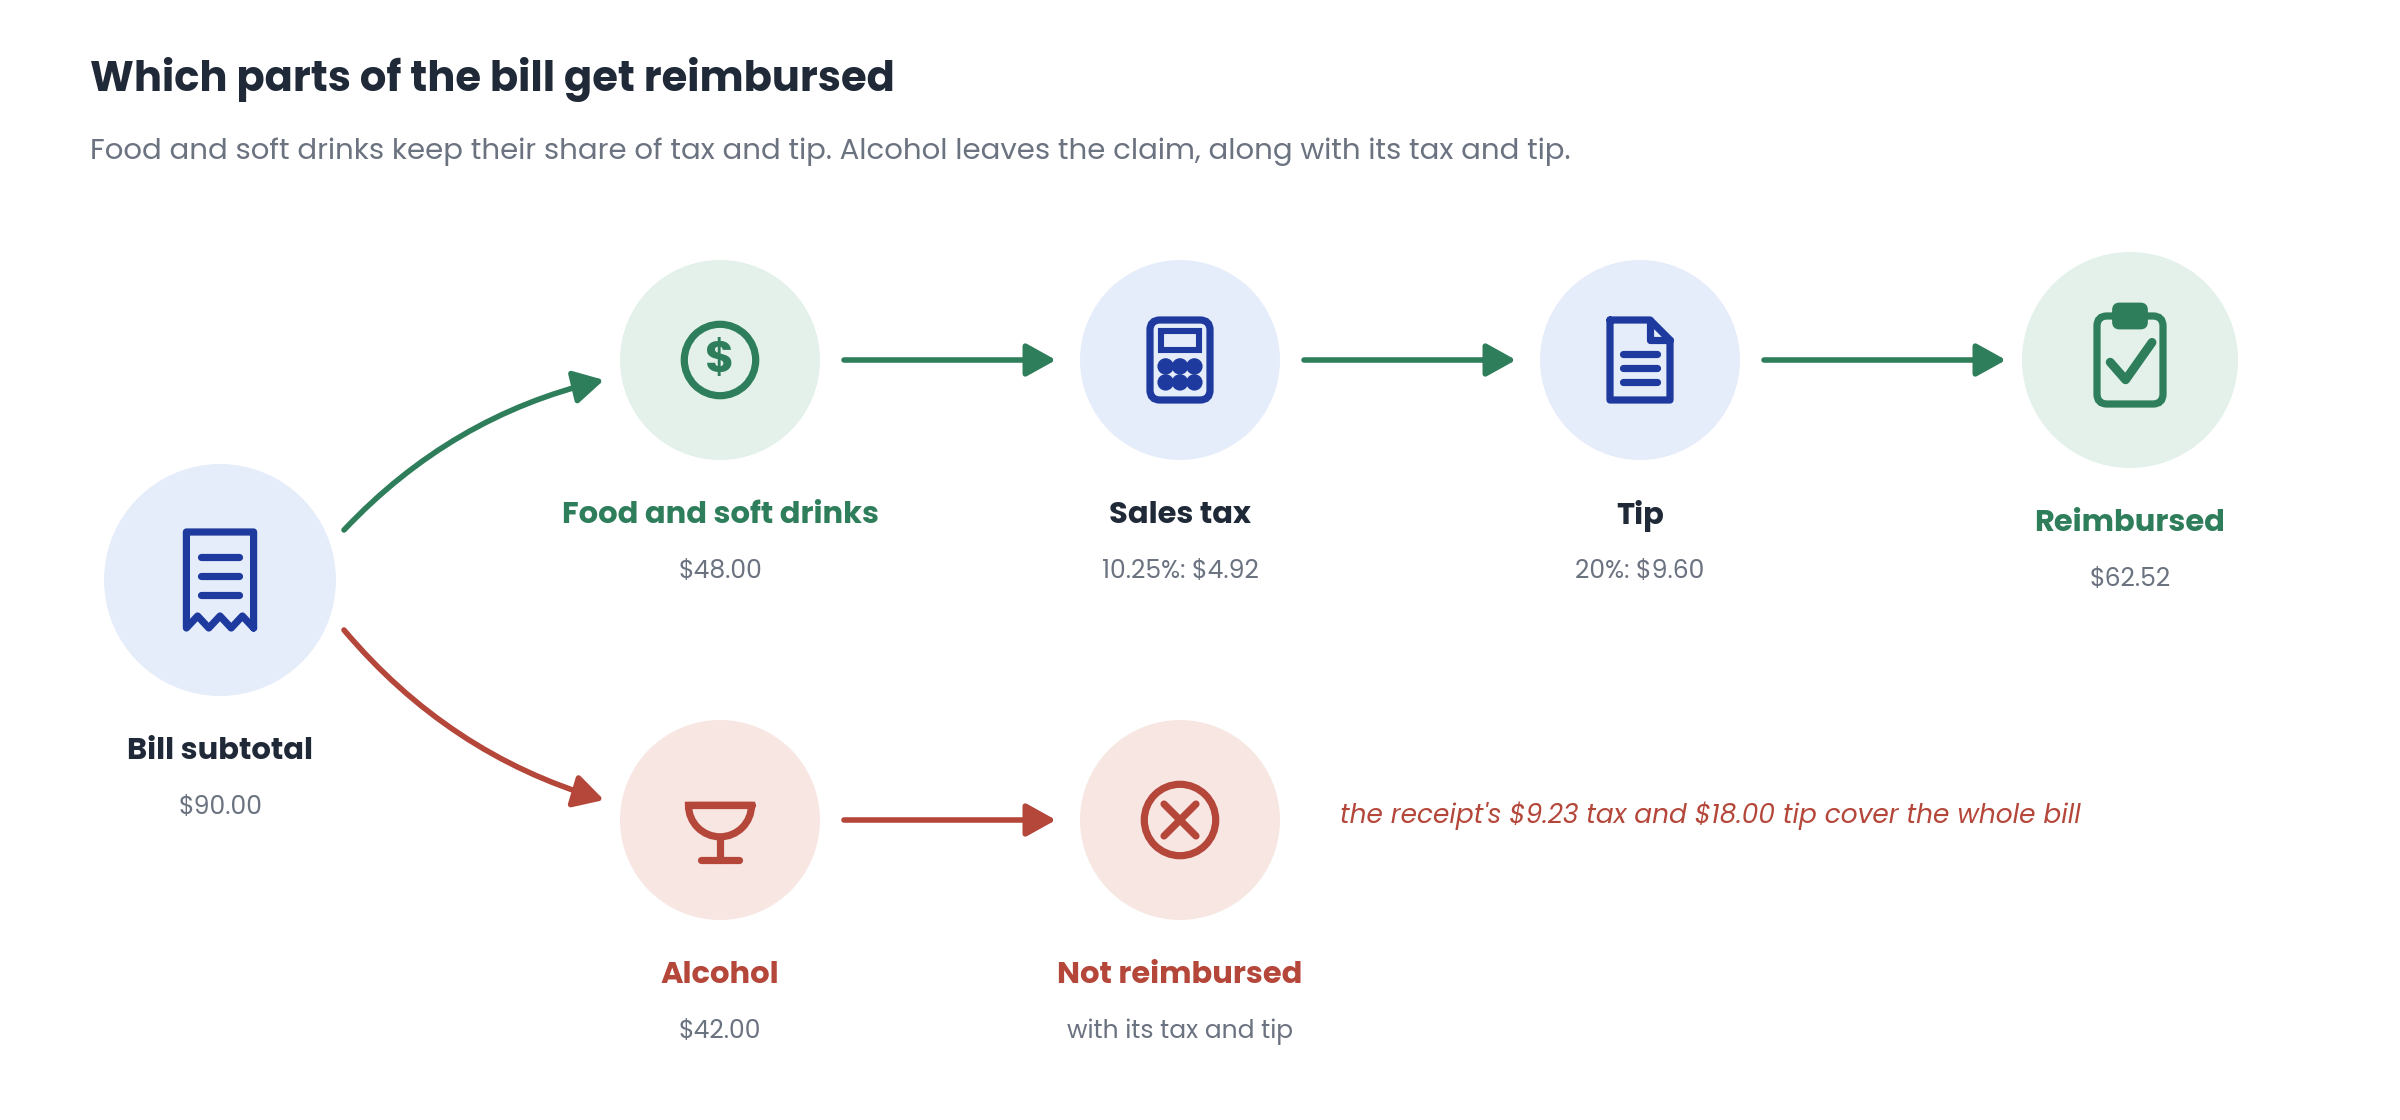

In [38]:
reimbursable_subtotal = 14.00 + 17.00 + 12.00 + 5.00    # Buffalo Wings + Margherita Flatbread + Caesar Salad + Sparkling Water
sales_tax = round(reimbursable_subtotal * 0.1025, 2)    # 10.25% sales tax rate printed on the receipt
tip = round(reimbursable_subtotal * 0.20, 2)            # 20% tip, within the policy's 15 to 20% guideline
expected_total = round(reimbursable_subtotal + sales_tax + tip, 2)

print(f"Reimbursable subtotal: ${reimbursable_subtotal:,.2f}")
print(f"Sales tax:             ${sales_tax:,.2f}")
print(f"Tip:                   ${tip:,.2f}")
print(f"Expected total:        ${expected_total:,.2f}")

Reimbursable subtotal: $48.00
Sales tax:             $4.92
Tip:                   $9.60
Expected total:        $62.52


## **7.4 Processing the Claim**

In [39]:
result = process_claim(agent_workflow, input_bill_path)
print(f"Tools called: {get_tool_sequence(result)}\n")
display(Markdown(get_report(result)))

Tools called: ['text_extractor', 'categorizer', 'verifier', 'calculator', 'calculator', 'calculator', 'calculator']



# Expense Claim Report
**Employee Name:** Emily Carter
**Expense Type:** Restaurant
**Date:** 10/08/2026
**Check No:** 4821
**Restaurant:** WICKER PARK TAVERN, 1548 N Milwaukee Ave, Chicago, IL 60622

## Reimbursable Items
| Item | Category | Quantity | Amount (USD) |
| --- | --- | --- | --- |
| Buffalo Wings | Food | 1 | $14.00 |
| Margherita Flatbread | Food | 1 | $17.00 |
| Caesar Salad | Food | 1 | $12.00 |
| Sparkling Water | Non-Alcoholic Drinks | 1 | $5.00 |

## Excluded Items
| Item | Category | Amount (USD) | Reason |
| --- | --- | --- | --- |
| Craft IPA | Alcoholic Drinks | $16.00 | Alcoholic beverages are strictly non-reimbursable. |
| Moscow Mule | Alcoholic Drinks | $13.00 | Alcoholic beverages are strictly non-reimbursable. |
| House Cabernet Gls | Alcoholic Drinks | $13.00 | Alcoholic beverages are strictly non-reimbursable. |

## Reimbursement Summary
- Reimbursable Subtotal: $48.00
- Sales Tax (10.25%): $4.92
- Tip (20%): $9.60
- **Total Amount to Be Reimbursed: $62.52**

Let us inspect the full message trace. Each AI message with tool calls is a reason step, and each tool message is an observation.

In [40]:
for message in result["messages"]:
    message.pretty_print()

================================ System Message ================================


You process restaurant receipts into expense claim reports for the finance team.

Steps:
1. Use text_extractor on the receipt image file.
2. Use categorizer on the extracted text.
3. Use verifier on the categorized items.
4. Use calculator for every amount below. Never compute amounts yourself.
   - Reimbursable subtotal = sum of the reimbursable item amounts.
   - Sales tax = reimbursable subtotal x the sales tax rate printed on the receipt.
   - Tip = reimbursable subtotal x the tip percentage printed on the receipt.
     Reimburse the tip only if that percentage is at or below the policy's maximum tip rate from the verifier.
   - Total = reimbursable subtotal + sales tax + tip.
   Round each amount to 2 decimal places.
   Do not reuse the subtotal, tax, or tip amounts printed on the receipt: they include the excluded items.

Present the final report in this markdown format and output nothing else:

# 

## **7.5 Comparing with the Expected Reimbursement**

In [41]:
def compare_with_expected(label: str, result):
    agent_total = extract_total(get_report(result))
    agent_text = f"${agent_total:,.2f}" if agent_total is not None else "missing"
    match = "Yes" if agent_total is not None and abs(agent_total - expected_total) < 0.01 else "No"
    print(f"{label:<22} Expected: ${expected_total:,.2f} | Agent: {agent_text} | Match: {match}")

In [42]:
compare_with_expected("Without reflection", result)

Without reflection     Expected: $62.52 | Agent: $62.52 | Match: Yes


## **7.6 A Narrow Task with Fewer Tools**

Tool selection also lets the same agent handle narrow tasks. For a calculation question, we select only one tool, so the LLM sees only the calculator.

In [43]:
question = "The reimbursable subtotal is $48.00. What is the 20% tip on it?"
quick_result = agent_workflow.invoke({
    "messages": [SystemMessage(content="Answer the question. Use the calculator for any math."),
                 HumanMessage(content=question)],
    "query": question,
    "num_tools": 1,
})

selected = [tool_registry[tool_id].name for tool_id in quick_result["selected_tools"]]
print(f"Selected tools: {selected}")
print(f"Tools called: {get_tool_sequence(quick_result)}")
print(f"Answer: {get_report(quick_result)}")

Selected tools: ['calculator']
Tools called: ['calculator']
Answer: The 20% tip is **$9.60**.


# **8. Adding Reflection**

The agent writes the report in one pass, so a wrong category, or tax and tip computed on the full bill, goes straight into the final report. This receipt has a common trap: a "Moscow Mule" can sound like a soft drink, but it is a vodka cocktail, so it is alcoholic.

As covered in 14.17 *Reflective Reasoning: Planning and Refinement in AI Agents*, reflection adds a review step: generate a draft, evaluate it against criteria, and refine it. We add a `reflect` node that reviews the draft against the policy and the verifier's output.

- If the draft passes, the workflow ends.
- If not, the reviewer's feedback goes back to the planner, which revises the report.
- `MAX_REFLECTIONS` caps the number of reviews so the loop always ends.

The diagram below shows the workflow with the reflection step added.

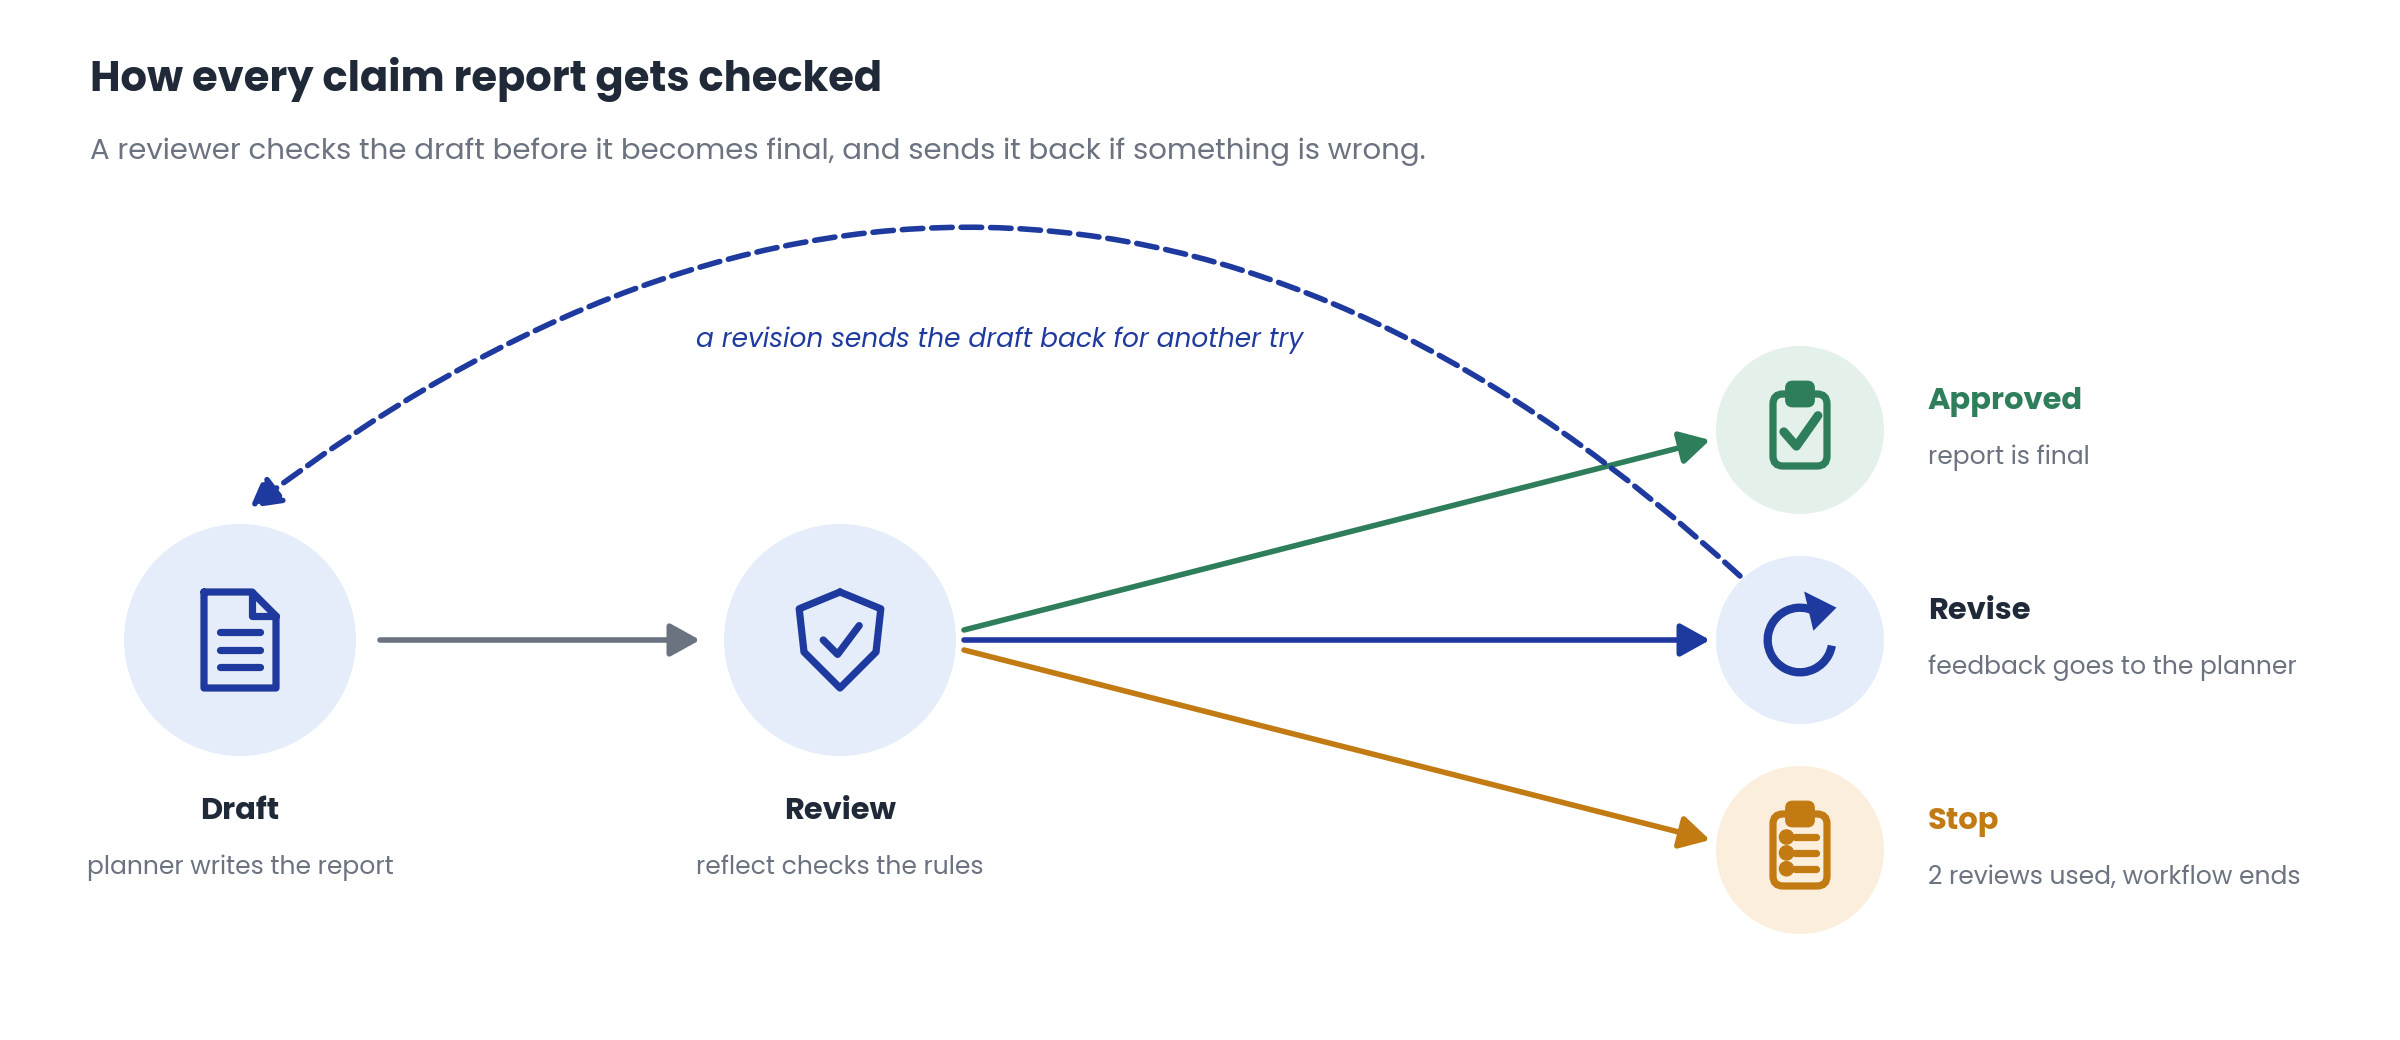

In [44]:
MAX_REFLECTIONS = 2

REVIEW_SYSTEM_MESSAGE = """
You are a senior finance reviewer. Check the draft expense claim report against the company policy
and the verifier output below. Check that:
1. No alcoholic drinks appear among the reimbursable items. Beer, wine, and cocktails such as a Moscow Mule count as alcoholic.
2. The reimbursable subtotal equals the sum of the reimbursable items.
3. Sales tax uses the receipt's tax rate on the reimbursable subtotal only, not on the full bill.
4. The tip uses the receipt's tip percentage on the reimbursable subtotal only, and that percentage is within the policy's tip limit.
5. The total equals subtotal + sales tax + tip, and every field in the report is filled in.

Return valid JSON only (double quotes, no code fences):
{"approved": true or false, "feedback": "<what is wrong and how to fix it, or 'No issues found.'>"}
"""

In [45]:
def reflect(state: AgentState):
    draft_report = state["messages"][-1].content

    # Gather the verifier output from this run and the key policy sections
    verifier_outputs = [m.content for m in state["messages"] if isinstance(m, ToolMessage) and m.name == "verifier"]
    policy_chunks = company_policy_vector_store.similarity_search(
        "alcoholic drinks non-reimbursable tips and gratuities", k=4
    )
    policy_text = "\n\n".join(chunk.page_content for chunk in policy_chunks)

    review = llm.invoke([
        SystemMessage(content=REVIEW_SYSTEM_MESSAGE + f"\nCompany Policy:\n{policy_text}"),
        HumanMessage(content=f"Verifier output:\n{verifier_outputs[-1] if verifier_outputs else 'Not available'}"
                             f"\n\nDraft report:\n{draft_report}")
    ])

    try:
        verdict = parse_json(review.content)
    except json.JSONDecodeError:
        verdict = {"approved": False, "feedback": review.content}

    update = {
        "reflection_count": state.get("reflection_count", 0) + 1,
        "approved": bool(verdict.get("approved")),
        "review_notes": state.get("review_notes", []) + [verdict.get("feedback", "")],
    }

    # Send feedback back to the planner only when the draft needs revision
    if not update["approved"]:
        update["messages"] = [HumanMessage(content=(
            f"Reviewer feedback: {verdict.get('feedback', '')}\n"
            "Revise the report. Use the calculator for any corrected amounts and return the full report in the same format."
        ))]
    return update

With reflection, the planner has three possible next steps, so `tools_condition` no longer covers the routing. We write two routing functions, extending the `should_continue` idea from the Week 14 hands-on notebook:

- `route_after_planner`: tool calls go to `tools`; a finished draft goes to `reflect` while reviews remain; otherwise the workflow ends.
- `route_after_reflect`: an approved draft ends the workflow; otherwise the planner revises it.

In [46]:
def route_after_planner(state: AgentState):
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        return "tools"
    if state.get("reflection_count", 0) < MAX_REFLECTIONS:
        return "reflect"
    return END


def route_after_reflect(state: AgentState):
    return END if state.get("approved") else "planner"

In [47]:
reflective_workflow = StateGraph(AgentState)

# Nodes
reflective_workflow.add_node("select_tools", select_tools)
reflective_workflow.add_node("planner", planner)
reflective_workflow.add_node("tools", tool_node)
reflective_workflow.add_node("reflect", reflect)

# Edges
reflective_workflow.add_edge(START, "select_tools")
reflective_workflow.add_edge("select_tools", "planner")
reflective_workflow.add_conditional_edges("planner", route_after_planner, ["tools", "reflect", END])
reflective_workflow.add_edge("tools", "planner")
reflective_workflow.add_conditional_edges("reflect", route_after_reflect, ["planner", END])

reflective_agent = reflective_workflow.compile()

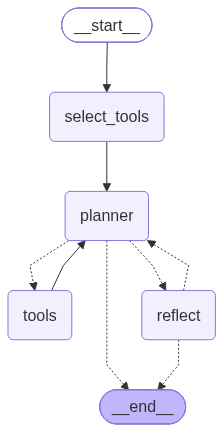

In [48]:
# Visualize the reflective workflow
# Drawing the graph calls an online service, so we skip it if there is no internet access
try:
    display(Image(reflective_agent.get_graph().draw_mermaid_png()))
except Exception:
    print("Could not draw the graph without internet access. The diagram above shows the same workflow.")

## **8.1 Running the Reflective Agent**

In [49]:
reflective_result = process_claim(reflective_agent, input_bill_path)

print(f"Tools called: {get_tool_sequence(reflective_result)}")
print(f"Reviews: {reflective_result['reflection_count']} | Approved: {reflective_result['approved']}")
for i, note in enumerate(reflective_result["review_notes"], start=1):
    print(f"Review {i}: {note}")

Tools called: ['text_extractor', 'categorizer', 'verifier', 'calculator', 'calculator', 'calculator', 'calculator']
Reviews: 1 | Approved: True
Review 1: No issues found.


In [50]:
display(Markdown(get_report(reflective_result)))

# Expense Claim Report
**Employee Name:** Emily Carter
**Expense Type:** Restaurant
**Date:** 10/08/2026
**Check No:** 4821
**Restaurant:** WICKER PARK TAVERN, 1548 N Milwaukee Ave, Chicago, IL 60622

## Reimbursable Items
| Item | Category | Quantity | Amount (USD) |
| --- | --- | --- | --- |
| Buffalo Wings | Food | 1 | $14.00 |
| Margherita Flatbread | Food | 1 | $17.00 |
| Caesar Salad | Food | 1 | $12.00 |
| Sparkling Water | Non-Alcoholic Drinks | 1 | $5.00 |

## Excluded Items
| Item | Category | Amount (USD) | Reason |
| --- | --- | --- | --- |
| Craft IPA | Alcoholic Drinks | $16.00 | Alcoholic beverages are strictly non-reimbursable. |
| Moscow Mule | Alcoholic Drinks | $13.00 | Alcoholic beverages are strictly non-reimbursable. |
| House Cabernet Gls | Alcoholic Drinks | $13.00 | Alcoholic beverages are strictly non-reimbursable. |

## Reimbursement Summary
- Reimbursable Subtotal: $48.00
- Sales Tax (10.25%): $4.92
- Tip (20%): $9.60
- **Total Amount to Be Reimbursed: $62.52**

## **8.2 Comparing Both Agents**

In [51]:
compare_with_expected("Without reflection", result)
compare_with_expected("With reflection", reflective_result)

Without reflection     Expected: $62.52 | Agent: $62.52 | Match: Yes
With reflection        Expected: $62.52 | Agent: $62.52 | Match: Yes


## **8.3 Testing the Reviewer on a Flawed Draft**

When the agent gets the claim right on the first pass, the reviewer approves it and reflection changes nothing. To see the reviewer catch a mistake, we hand it a draft with the most common error on this receipt: sales tax and tip copied from the receipt, which charges them on the full $90.00 bill, including the drinks.

The draft below claims $75.23 instead of $62.52. The reviewer should reject it and explain the fix.

In [52]:
# A draft that reuses the receipt's own tax ($9.23) and tip ($18.00), which cover the full bill
flawed_report = """# Expense Claim Report
**Employee Name:** Emily Carter
**Expense Type:** Restaurant
**Date:** 10/08/2026
**Check No:** 4821
**Restaurant:** WICKER PARK TAVERN, 1548 N Milwaukee Ave, Chicago, IL 60622

## Reimbursable Items
| Item | Category | Quantity | Amount (USD) |
| --- | --- | --- | --- |
| Buffalo Wings | Food | 1 | $14.00 |
| Margherita Flatbread | Food | 1 | $17.00 |
| Caesar Salad | Food | 1 | $12.00 |
| Sparkling Water | Non-Alcoholic Drinks | 1 | $5.00 |

## Excluded Items
| Item | Category | Amount (USD) | Reason |
| --- | --- | --- | --- |
| Craft IPA | Alcoholic Drinks | $16.00 | Alcoholic beverages are strictly non-reimbursable. |
| Moscow Mule | Alcoholic Drinks | $13.00 | Alcoholic beverages are strictly non-reimbursable. |
| House Cabernet Gls | Alcoholic Drinks | $13.00 | Alcoholic beverages are strictly non-reimbursable. |

## Reimbursement Summary
- Reimbursable Subtotal: $48.00
- Sales Tax (10.25%): $9.23
- Tip (20%): $18.00
- **Total Amount to Be Reimbursed: $75.23**
"""

# Reuse the messages from the reflective run (they hold the verifier output) and add the flawed draft at the end
test_state = {
    "messages": list(reflective_result["messages"]) + [AIMessage(content=flawed_report)],
    "reflection_count": 0,
    "review_notes": [],
}

review = reflect(test_state)
print(f"Approved: {review['approved']}")
print(f"Reviewer feedback: {review['review_notes'][-1]}")

Approved: False
Reviewer feedback: Sales tax is incorrect. The reimbursable items sum to $48.00, and 10.25% tax on that subtotal is $4.92, not $9.23. The tip is also incorrect: 20% of $48.00 is $9.60, not $18.00. The corrected total is $48.00 + $4.92 + $9.60 = $62.52. All reimbursable and excluded items are correctly classified, and the 20% tip rate is within the policy limit.


# **9. Observations**

Use the outputs above to discuss:

- **Extraction:** Did the text extractor read every item and amount correctly from the angled photo?
- **Categorization:** Did the categorizer mark the Craft IPA, Moscow Mule, and House Cabernet as alcoholic?
- **Tax and tip:** Did the agent compute sales tax and tip on the eligible $48.00, or did it reuse the receipt's $9.23 tax and $18.00 tip, which cover the full $90.00 bill?
- **Tool order:** Did the agent call the tools in the expected order (extractor, categorizer, verifier, calculator)? How many calculator calls did it make?
- **Reflection:** Did the reviewer send the agent's draft back? In section 8.3, did it reject the flawed draft and name the tax and tip error? What did reflection cost in extra LLM calls?
- **Tool selection:** Which tool did the narrow question select? What would happen if `num_tools` were too small for a full claim?

> **Note:** LLM outputs vary between runs. Run the claim more than once before drawing conclusions about accuracy.

# **10. Business Insights and Recommendations**

## **10.1 Business Insights**

1. **The agent automates the full review chain.** One receipt photo becomes a formatted claim report with alcohol excluded and taxes recalculated on the eligible amount, the same steps a finance reviewer performs by hand.
2. **Splitting work into tools makes errors traceable.** When a total is wrong, the tool trace shows whether the problem came from extraction, categorization, policy verification, or calculation.
3. **Tax and tip must follow the eligible amount.** The receipt's tax and tip cover the whole bill, including the drinks. The agent has to recompute both on the eligible items, a step that is easy to skip by hand.
4. **Reflection trades cost for reliability.** Each review adds at least one LLM call, but it catches errors such as a cocktail treated as non-alcoholic or tax and tip left at the full-bill amounts.
5. **Tool selection keeps the agent scalable.** As finance adds tools (mileage, hotels, airfare, duplicate checks), the agent sees only the tools relevant to each task.

## **10.2 Recommendations**

1. **Keep a human in the loop for exceptions.** Route claims to a finance reviewer when the reviewer node does not approve after the maximum reviews, when the claim exceeds a set amount, or when the receipt photo is unreadable.
2. **Build a labeled test set before rollout.** One receipt cannot show how reliable the agent is. Collect a few hundred past receipts with their approved reimbursements and measure how often the agent matches them, by restaurant and receipt type.
3. **Log every tool trace.** Store the tool calls and results with each claim so auditors can see how the agent reached each amount.
4. **Add tools for other expense types.** Extend the registry with tools for mileage, hotel, and airfare claims, and a tool that flags duplicate receipt numbers.
5. **Make the policy precise.** The policy gives tips as "typically up to 15-20%" and asks for justification of "excessive spending" without a number. Exact limits per meal and per tip would let the agent apply them without guessing.
6. **Store tax rates per location.** Sales tax on restaurant meals differs by city and state. Keep the rates in a reference table the agent can look up, so it can check the rate printed on each receipt.

<font size=6 color="#4682B4">Power Ahead!</font>
___